In [1]:
import numpy as np
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
import pandas as pd
import glob 
import os
import pickle
from pathlib import Path
import time
import pandas as pd

import scipy.signal as signal
import scipy.fft as fft
import scipy.stats as stats

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import glob 
import pywt #PyWavelets package
import matplotlib.colors as colors
from matplotlib.colors import LogNorm



from data_process import select_df,read_and_process_data ,fac_decompose_dB

In [2]:
with open('data/sec-krtp-file_time_index.csv','rb') as f:
    index_df = pickle.load(f)

In [3]:
with open(Path("/Users/chengzhimao/Documents/Code/saturn2025/cassini_ksm_2004_2017_60s.pkl"), "rb") as f:
    cassini_location = pickle.load(f)

In [3]:
## load in the location data of cassini from "cassini_j2000_saturn_centered_2004_2017_60s.pkl"
with open("cassini_j2000_saturn_centered_2004_2017_60s.pkl", "rb") as f:
    cassini_location = pickle.load(f)

# one event

In [4]:
start_time=pd.to_datetime('2010-12-21 02:50:00')
end_time=pd.to_datetime('2010-12-21 03:20:00')
df=select_df(start_time,end_time)
df=read_and_process_data(start_time,end_time)

In [18]:
df["BTOTAL"].mean()

np.float64(185.76593666666668)

In [5]:
# cyclotron frequency of H2O+ ion in Saturn's magnetosphere: qB/(2 pi m)
cyclotron_freq=  (df["BTOTAL"].mean()*1e-9 * 1.6e-19) /(2*np.pi* 18*1.66e-27 )

<>:49: SyntaxWarning: invalid escape sequence '\O'
<>:49: SyntaxWarning: invalid escape sequence '\O'
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_40668/2977890842.py:49: SyntaxWarning: invalid escape sequence '\O'
  ax.axvspan(0.5*cyclotron_freq, 2*cyclotron_freq, color='C2', alpha=0.1, label='0.5-2 $\Omega_{H_2O^+}$ range')
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_40668/2977890842.py:27: RuntimeWarning: divide by zero encountered in divide
  Power_parallel=np.abs(F_parallel)**2/(N*freqs_parallel)
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_40668/2977890842.py:28: RuntimeWarning: divide by zero encountered in divide
  Power_perp=(np.abs(F_perpendicular_1)**2+np.abs(F_perpendicular_2)**2)/(N*freqs_perpendicular)


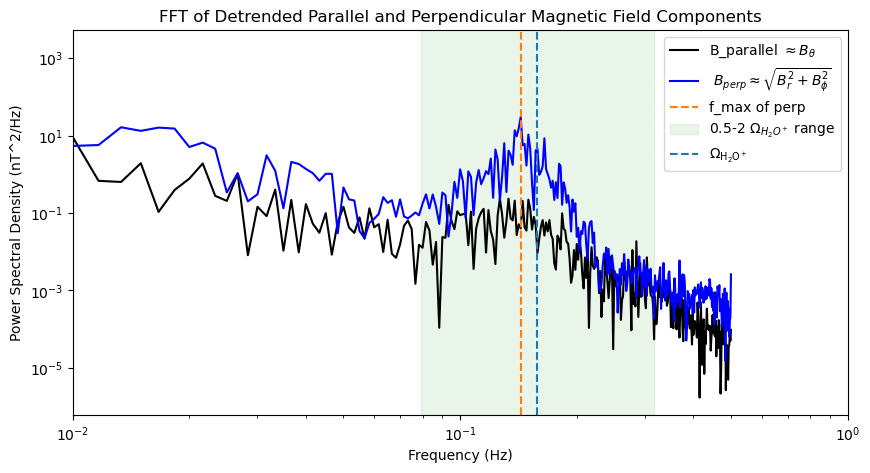

In [7]:
# do the same to dB_parallel and dB_perpendicular components
# col=['dB_parallel','dB_perpendicular']
# F_list=[]
# for c in col:
#     fn=df[c].values
#     N=len(fn)
#     T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
#     F1 = fft.rfft(fn)
#     freqs = fft.rfftfreq(N,d=T)
#     F_list.append((freqs,F1))  

fn=df['dB_parallel'].values
N=len(fn)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
F_parallel = fft.rfft(fn)
freqs_parallel = fft.rfftfreq(N,d=T)

fn=df['dB_perpendicular_1'].values
F_perpendicular_1 = fft.rfft(fn)
freqs_perpendicular = fft.rfftfreq(N,d=T)   

fn=df['dB_perpendicular_2'].values
F_perpendicular_2 = fft.rfft(fn)
freqs_perpendicular = fft.rfftfreq(N,d=T)  


Power_parallel=np.abs(F_parallel)**2/(N*freqs_parallel)
Power_perp=(np.abs(F_perpendicular_1)**2+np.abs(F_perpendicular_2)**2)/(N*freqs_perpendicular)
    
    
freq=freqs_parallel[1]-freqs_parallel[0]


color=['black','blue']

fig,ax=plt.subplots(figsize=(10,5))
ax.plot(freqs_parallel,Power_parallel,label=r'B_parallel $ \approx B_{\theta}$',color=color[0])
ax.plot(freqs_perpendicular,Power_perp,label=r' $B_{perp} \approx \sqrt{ B_{r}^2+ B_{\phi}^2}$',color=color[1])

    
# identify maximum peak within a certain frequency range (e.g., 1/2 to 2 times the cyclotron frequency)
range_mask = (freqs_parallel > 0.5*cyclotron_freq) & (freqs_parallel < 2*cyclotron_freq)
idx=np.argmax(Power_perp[range_mask])
max_peak_freq = freqs_perpendicular[range_mask][idx]
ax.axvline(max_peak_freq,color='C1',linestyle='--',label=f'f_max of perp')  


#plot the shaded region corresponding to the frequency range of interest
ax.axvspan(0.5*cyclotron_freq, 2*cyclotron_freq, color='C2', alpha=0.1, label='0.5-2 $\Omega_{H_2O^+}$ range')


#plot a vertical line at the cyclotron frequency
ax.axvline(cyclotron_freq,color='C0',linestyle='--',label=r'$\Omega_{\mathrm{H_2O^+}}$')    
ax.set_xlabel('Frequency (Hz)')
ax.set_title('FFT of Detrended Parallel and Perpendicular Magnetic Field Components')
ax.set_xscale('log')
ax.set_xlim(1e-2,1e0) # Limit x-axis to Nyquist frequency
ax.set_ylabel('Power Spectral Density (nT^2/Hz)')
ax.set_yscale('log')
# ax.set_ylim(None,5e-2)
ax.legend()
plt.show()


# one event check

In [ ]:
#detrend is 1200s. so the start time is 10min eariler than intended, and end time is 10min later.

In [ ]:
start_time=pd.to_datetime('2010-12-21 01:50:00')
end_time=pd.to_datetime('2010-12-21 02:20:00')

df=read_and_process_data(start_time,end_time)
check_ICW(df)



# the I/O cassini data is extremely slow.

# make it batch operation

In [4]:
def check_ICW(df):
    cols = ['TIME', 'BTOTAL', 'dB_parallel', 
            'dB_perpendicular_1', 'dB_perpendicular_2']

    if df is None or not set(cols).issubset(df.columns):
        return False

    df = df[cols].replace([np.inf, -np.inf], np.nan).dropna()
    if len(df) < 2:
        return False

    # H2O+ cyclotron frequency: qB / (2πm)
    cyclotron_freq = df['BTOTAL'].mean() * 1e-9 * 1.6e-19 / (
        2 * np.pi * 18 * 1.66e-27
    )

    dt = df['TIME'].diff().dt.total_seconds().mean()
    if not np.isfinite(dt) or dt <= 0 or not np.isfinite(cyclotron_freq) or cyclotron_freq <= 0:
        return False

    signals = df[['dB_parallel', 'dB_perpendicular_1', 
                  'dB_perpendicular_2']].to_numpy()
    N = len(signals)

    freqs = fft.rfftfreq(N, d=dt)
    PSDtotal = np.zeros_like(freqs)

    nonzero = freqs > 0
    F = fft.rfft(signals, axis=0)
    PSDtotal[nonzero] = np.sum(np.abs(F[nonzero])**2, axis=1) / (
        N * freqs[nonzero]
    )

    f0 = 0.5 * cyclotron_freq
    band = (freqs >= f0) & (freqs <= 2 * cyclotron_freq)

    if not np.any(band):
        return False

    finite = nonzero & np.isfinite(PSDtotal)
    if np.sum(finite) < 2:
        return False

    power_at_f0 = np.interp(f0, freqs[finite], PSDtotal[finite])
    max_power = np.nanmax(PSDtotal[band])

    return np.isfinite(power_at_f0) and power_at_f0 > 0 and max_power / power_at_f0 > 2

In [5]:
def batch_check_ICW(start_time, end_time, index_df, step='10min', section='10min'):
    start_time = pd.to_datetime(start_time)
    end_time = pd.to_datetime(end_time)

    section = pd.Timedelta(section)
    step = pd.Timedelta(step)

    selected = index_df[
        (index_df['end_time'] >= start_time) &
        (index_df['start_time'] <= end_time)
    ].copy()

    if len(selected) == 0:
        return pd.DataFrame(columns=['interval_start', 'interval_end', 'is_ICW'])

    result_dfs = []

    for file in selected['file_name']:
        try:
            df = pd.read_csv(
                file,
                sep=r'\s+',
                names=['TIME', 'BR', 'BTHETA', 'BPHI', 'BTOTAL', 'NPTS']
            )
        except Exception as e:
            print(f"[WARN] Could not read {file}: {e}")
            continue

        df['TIME'] = pd.to_datetime(df['TIME'])

        # Keep only the requested global time range
        df = df[
            (df['TIME'] >= start_time) &
            (df['TIME'] <= end_time)
        ].copy()

        if len(df) < 2:
            continue

        file_start = df['TIME'].min()
        file_end = df['TIME'].max()

        try:
            # Run FAC decomposition only for this file
            df_fac = fac_decompose_dB(df, file_start, file_end)
        except Exception as e:
            print(f"[WARN] FAC decomposition failed for {file}: {e}")
            continue

        if len(df_fac) < 2:
            continue

        df_fac = df_fac.set_index('TIME').sort_index()

        starts = pd.date_range(
            df_fac.index.min(),
            df_fac.index.max() - section,
            freq=step
        )

        rows = []

        for t0 in starts:
            t1 = t0 + section
            df_section = df_fac.loc[t0:t1].reset_index()

            if len(df_section) < 2:
                continue

            try:
                is_icw = check_ICW(df_section)
            except Exception as e:
                print(f"[WARN] check_ICW failed for {t0} to {t1} in {file}: {e}")
                is_icw = False

            rows.append({
                'interval_start': t0,
                'interval_end': t1,
                'is_ICW': is_icw,
                'file_name': file
            })

        if rows:
            result_dfs.append(pd.DataFrame(rows))

    if not result_dfs:
        return pd.DataFrame(columns=['interval_start', 'interval_end', 'is_ICW', 'file_name'])

    result = (
        pd.concat(result_dfs, ignore_index=True)
        .drop_duplicates(subset=['interval_start', 'interval_end'])
        .sort_values('interval_start')
        .reset_index(drop=True)
    )

    return result

In [ ]:
# old
def batch_check_ICW(start_time, end_time, index_df, step='10min', section='10min'):
    start_time = pd.to_datetime(start_time)
    end_time = pd.to_datetime(end_time)

    selected = index_df[
        (index_df['end_time'] >= start_time) &
        (index_df['start_time'] <= end_time)
    ]

    if len(selected) == 0:
        return pd.DataFrame(columns=['interval_start', 'interval_end', 'is_ICW'])

    dfs = []
    for file in selected['file_name']:
        df = pd.read_csv(
            file,
            sep=r'\s+',
            names=['TIME', 'BR', 'BTHETA', 'BPHI', 'BTOTAL', 'NPTS']
        )
        df['TIME'] = pd.to_datetime(df['TIME'])

        df = df[
            (df['TIME'] >= start_time) &
            (df['TIME'] <= end_time)
        ]

        dfs.append(df)

    df_all = (
        pd.concat(dfs, ignore_index=True)
        .drop_duplicates(subset='TIME')
        .sort_values('TIME')
        .reset_index(drop=True)
    )

    if len(df_all) < 2:
        return pd.DataFrame(columns=['interval_start', 'interval_end', 'is_ICW'])

    # Run your 20-min running subtraction / FAC decomposition once
    df_fac = fac_decompose_dB(df_all, start_time, end_time)

    if len(df_fac) < 2:
        return pd.DataFrame(columns=['interval_start', 'interval_end', 'is_ICW'])

    df_fac = df_fac.set_index('TIME').sort_index()

    section = pd.Timedelta(section)
    step = pd.Timedelta(step)

    starts = pd.date_range(
        df_fac.index.min(),
        df_fac.index.max() - section,
        freq=step
    )

    rows = []

    for t0 in starts:
        t1 = t0 + section
        df_section = df_fac.loc[t0:t1].reset_index()

        rows.append({
            'interval_start': t0,
            'interval_end': t1,
            'is_ICW': check_ICW(df_section)
        })

    return pd.DataFrame(rows)

In [5]:
def merge_ICW_with_location(labels_df, cassini_location, tolerance='5min'):
    labels = labels_df.copy()
    loc = cassini_location.copy()

    labels['interval_start'] = pd.to_datetime(labels['interval_start']).dt.tz_localize(None)
    labels['interval_end'] = pd.to_datetime(labels['interval_end']).dt.tz_localize(None)
    loc['utc'] = pd.to_datetime(loc['utc']).dt.tz_localize(None)

    # Use interval midpoint as representative time
    labels['time'] = labels['interval_start'] + (
        labels['interval_end'] - labels['interval_start']
    ) / 2

    labels = labels.sort_values('time')
    loc = loc.sort_values('utc')

    # keep_cols = [
    #     'utc', 'x_ksm_Rs', 'y_ksm_Rs', 'z_ksm_Rs',
    #     'r_Rs', 'lat_deg', 'lon_deg'
    # ]
    # keep_cols = [c for c in keep_cols if c in loc.columns]

    merged = pd.merge_asof(
        labels,
        loc,
        left_on='time',
        right_on='utc',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

    return merged.dropna(subset=['r_Rs']).reset_index(drop=True)

In [7]:
def radial_ICW_statistics(ICW_loc_df, r_bins=None):
    df = ICW_loc_df.dropna(subset=['r_Rs', 'is_ICW']).copy()
    df['is_ICW'] = df['is_ICW'].astype(bool)

    if r_bins is None:
        r_bins = np.arange(0, np.nanmax(df['r_Rs']) + 1, 1)

    df['r_bin'] = pd.cut(df['r_Rs'], bins=r_bins)

    stat = df.groupby('r_bin', observed=True).agg(
        n_total=('is_ICW', 'size'),
        n_ICW=('is_ICW', 'sum'),
        r_mean=('r_Rs', 'mean')
    ).reset_index()

    stat['ICW_fraction'] = stat['n_ICW'] / stat['n_total']

    return stat

## 1D statistics of ICW distribution
To get the occurence of ICW in radial distance.
First, Cassini radial distance wrt time. For example each 10min.
Then each 10min, ICW or not 


In [22]:
print(labels_df)

                interval_start            interval_end  is_ICW  \
0      2004-05-14 00:10:24.500 2004-05-14 00:20:24.500   False   
1      2004-05-14 00:20:24.500 2004-05-14 00:30:24.500   False   
2      2004-05-14 00:30:24.500 2004-05-14 00:40:24.500   False   
3      2004-05-14 00:40:24.500 2004-05-14 00:50:24.500   False   
4      2004-05-14 00:50:24.500 2004-05-14 01:00:24.500   False   
...                        ...                     ...     ...   
665804 2017-08-31 22:55:21.500 2017-08-31 23:05:21.500   False   
665805 2017-08-31 23:05:21.500 2017-08-31 23:15:21.500   False   
665806 2017-08-31 23:15:21.500 2017-08-31 23:25:21.500   False   
665807 2017-08-31 23:25:21.500 2017-08-31 23:35:21.500   False   
665808 2017-08-31 23:35:21.500 2017-08-31 23:45:21.500   False   

                                                file_name  
0       data/_cassini-mag-cal-sec-krtp/04135_04240_00_...  
1       data/_cassini-mag-cal-sec-krtp/04135_04240_00_...  
2       data/_cassini-mag-c

### 2017


In [8]:
labels_df = batch_check_ICW(
    start_time='2017-01-01 00:00:00',
    end_time='2017-09-01 00:00:00',
    index_df=index_df
)

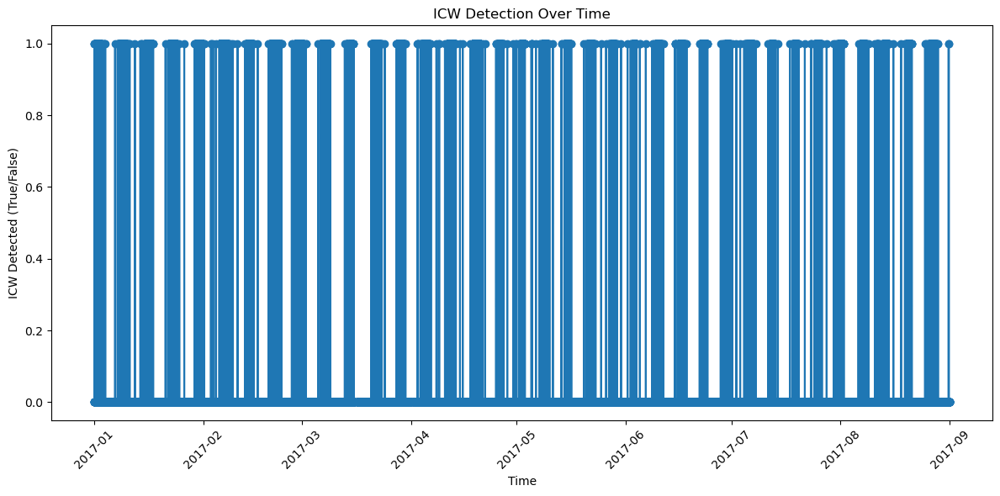

In [9]:
fig,ax=plt.subplots(figsize=(12,6))
ax.plot(labels_df['interval_start'],labels_df['is_ICW'],marker='o',linestyle='-')
ax.set_xlabel('Time')
ax.set_ylabel('ICW Detected (True/False)')
ax.set_title('ICW Detection Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# count the true percentage in labels_df['is_ICW']
print(f"ICW Detected in {labels_df['is_ICW'].mean()*100:.2f}% of intervals")

ICW Detected in 12.60% of intervals


In [14]:
ICW_loc_df = merge_ICW_with_location(labels_df, cassini_location)

In [13]:
radial_stat = radial_ICW_statistics(ICW_loc_df, r_bins=np.arange(0, 20, 0.1))

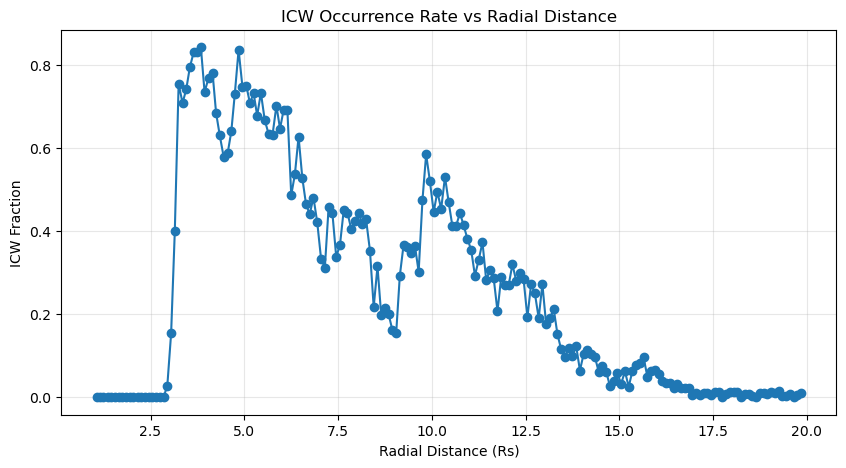

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(radial_stat['r_mean'], radial_stat['ICW_fraction'], marker='o')
ax.set_xlabel('Radial Distance (Rs)')
ax.set_ylabel('ICW Fraction')
ax.set_title('ICW Occurrence Rate vs Radial Distance')
ax.grid(True, alpha=0.3)

### 2004-2017

In [8]:
labels_df = batch_check_ICW(
    start_time='2004-04-01 00:00:00',
    end_time='2017-09-01 00:00:00',
    index_df=index_df
)

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_80366/3325047475.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['TIME'] = pd.to_datetime(df['TIME'])


In [9]:
labels_df

,interval_start,interval_end,is_ICW,file_name
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...
...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...


In [11]:
# save the labels_df to a pickle file, 2004 to 2017
with open('data/check_wave/ICW_labels_2004_2017.pkl', 'wb') as f:
    pickle.dump(labels_df, f)

In [16]:
ICW_loc_df = merge_ICW_with_location(labels_df, cassini_location)

,interval_start,interval_end,is_ICW,file_name,time,utc,et,x_ksm_km,y_ksm_km,z_ksm_km,...,y_ksm_Rs,z_ksm_Rs,r_Rs,L_approx,MLT_hr,MLAT_approx_deg,vx_ksm_km_s,vy_ksm_km_s,vz_ksm_km_s,speed_km_s
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:15:24.500,2004-05-14 00:15:00,1.377658e+08,9.801883e+06,-2.310318e+07,-3.317866e+06,...,-383.340786,-55.051867,420.038182,427.379606,7.532656,-7.531079,-2.230465,4.939001,1.033613,5.516980
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:25:24.500,2004-05-14 00:25:00,1.377664e+08,9.800545e+06,-2.310022e+07,-3.317228e+06,...,-383.291659,-55.041278,419.983360,427.322903,7.532644,-7.530610,-2.230430,4.930535,1.092985,5.520834
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:35:24.500,2004-05-14 00:35:00,1.377670e+08,9.799207e+06,-2.309727e+07,-3.316555e+06,...,-383.242612,-55.030118,419.928539,427.266045,7.532633,-7.530063,-2.230394,4.922673,1.148157,5.525000
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:45:24.500,2004-05-14 00:45:00,1.377676e+08,9.797869e+06,-2.309431e+07,-3.315851e+06,...,-383.193641,-55.018432,419.873716,427.209044,7.532620,-7.529444,-2.230359,4.915492,1.198597,5.529304
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:55:24.500,2004-05-14 00:55:00,1.377682e+08,9.796530e+06,-2.309137e+07,-3.315118e+06,...,-383.144737,-55.006270,419.818894,427.151913,7.532608,-7.528758,-2.230323,4.909062,1.243821,5.533563
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:00:21.500,2017-08-31 23:00:00,5.574925e+08,-7.557390e+05,1.113218e+04,7.314410e+05,...,0.184711,12.136473,17.451953,33.796193,23.943739,44.060861,3.624372,-1.054152,-1.087250,3.928030
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:10:21.500,2017-08-31 23:10:00,5.574931e+08,-7.535599e+05,1.049960e+04,7.307843e+05,...,0.174215,12.125578,17.418297,33.796424,23.946782,44.118150,3.639168,-1.054416,-1.101628,3.945747
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:20:21.500,2017-08-31 23:20:00,5.574937e+08,-7.513720e+05,9.866928e+03,7.301190e+05,...,0.163718,12.114538,17.384459,33.796538,23.949843,44.175642,3.654008,-1.054443,-1.116080,3.963491
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:30:21.500,2017-08-31 23:30:00,5.574943e+08,-7.491751e+05,9.234313e+03,7.294450e+05,...,0.153221,12.103355,17.350437,33.796535,23.952921,44.233339,3.668891,-1.054236,-1.130606,3.981262


In [45]:
radial_stat = radial_ICW_statistics(ICW_loc_df, r_bins=np.arange(0, 15, 0.05))

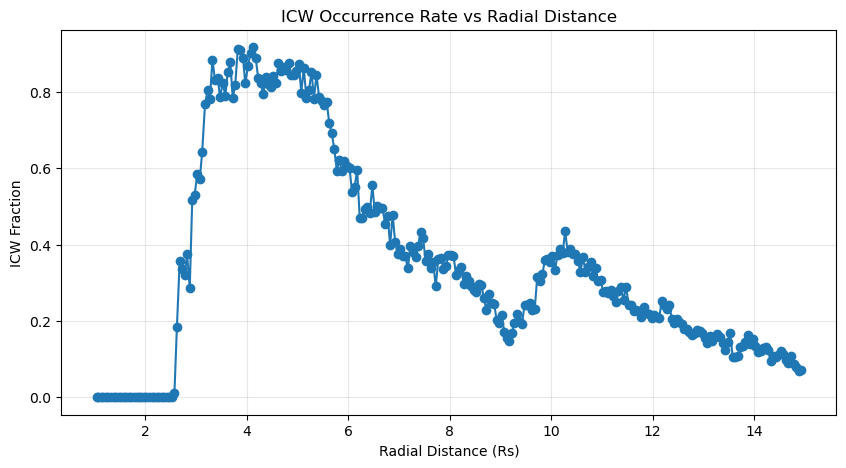

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(radial_stat['r_mean'], radial_stat['ICW_fraction'], marker='o')
ax.set_xlabel('Radial Distance (Rs)')
ax.set_ylabel('ICW Fraction')
ax.set_title('ICW Occurrence Rate vs Radial Distance')
ax.grid(True, alpha=0.3)

In [35]:
ICW_loc_df

,interval_start,interval_end,is_ICW,file_name,time,utc,x_ksm_Rs,y_ksm_Rs,z_ksm_Rs,r_Rs
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:15:24.500,2004-05-14 00:15:00,162.638271,-383.340786,-55.051867,420.038182
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:25:24.500,2004-05-14 00:25:00,162.616066,-383.291659,-55.041278,419.983360
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:35:24.500,2004-05-14 00:35:00,162.593861,-383.242612,-55.030118,419.928539
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:45:24.500,2004-05-14 00:45:00,162.571657,-383.193641,-55.018432,419.873716
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:55:24.500,2004-05-14 00:55:00,162.549452,-383.144737,-55.006270,419.818894
...,...,...,...,...,...,...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:00:21.500,2017-08-31 23:00:00,-12.539639,0.184711,12.136473,17.451953
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:10:21.500,2017-08-31 23:10:00,-12.503483,0.174215,12.125578,17.418297
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:20:21.500,2017-08-31 23:20:00,-12.467179,0.163718,12.114538,17.384459
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:30:21.500,2017-08-31 23:30:00,-12.430728,0.153221,12.103355,17.350437


# Automated several criteria

In [ ]:
# auxiliary functions for wave detection and analysis
E_CHARGE = 1.602176634e-19
AMU = 1.66053906660e-27


def _cyclotron_freq_hz(B_nT, mass_amu=18.0, charge_e=1.0):
    """
    Ion cyclotron frequency:
        f_ci = q B / (2 pi m)

    Default mass_amu=18 means H2O+.
    """
    B_T = float(B_nT) * 1e-9
    q = charge_e * E_CHARGE
    m = mass_amu * AMU
    return q * B_T / (2 * np.pi * m)


def _median_dt_seconds(time_series):
    dt = time_series.diff().dt.total_seconds().dropna()
    if len(dt) == 0:
        return np.nan
    return float(np.nanmedian(dt))


def one_sided_psd(x, dt, window='hann', remove_mean=True):
    """
    One-sided PSD using FFT.

    Parameters
    ----------
    x : array-like
        Input time series.
    dt : float
        Sampling interval in seconds.
    window : {'hann', 'boxcar', None}
        'hann' reduces spectral leakage.
        'boxcar' or None applies no taper.
    remove_mean : bool
        Subtract section mean before FFT.

    Returns
    -------
    freqs, psd
        Frequency array and one-sided PSD.
    """

    x = np.asarray(x, dtype=float)

    if len(x) < 4:
        return None, None

    if remove_mean:
        x = x - np.nanmean(x)

    n = len(x)

    if window in [None, 'boxcar']:
        w = np.ones(n)
    elif window == 'hann':
        w = np.hanning(n)
    else:
        raise ValueError("window must be 'hann', 'boxcar', or None")

    xw = x * w

    freqs = fft.rfftfreq(n, d=dt)
    X = fft.rfft(xw)

    psd = (np.abs(X) ** 2) * (2 * dt / np.sum(w ** 2))

    # Correct DC bin
    psd[0] *= 0.5

    # Correct Nyquist bin if it exists
    if n % 2 == 0:
        psd[-1] *= 0.5

    return freqs, psd


def _band_power(freqs, psd, fmin, fmax):
    mask = (
        (freqs >= fmin) &
        (freqs <= fmax) &
        np.isfinite(psd)
    )

    if np.sum(mask) < 2:
        return np.nan

    return float(np.trapz(psd[mask], freqs[mask]))


def _peak_frequency(freqs, psd, fmin, fmax):
    mask = (
        (freqs >= fmin) &
        (freqs <= fmax) &
        np.isfinite(psd)
    )

    if np.sum(mask) < 1:
        return np.nan, np.nan

    f_band = freqs[mask]
    p_band = psd[mask]

    i = np.nanargmax(p_band)

    return float(f_band[i]), float(p_band[i])


def _peak_prominence(freqs, psd, f_peak, fmin, fmax):
    """
    Simple peak/background ratio.
    Background excludes the candidate band.
    """
    if not np.isfinite(f_peak):
        return np.nan

    # the part we want. We want to exclude the interval [0.5*fmin, 2*fmax]. [0.5*fmin, 2*fmax] is the interval investigated for the peak.
    bg_mask = (
        (freqs > 0) &
        np.isfinite(psd) &
        (
            (freqs < 0.5 * fmin) |
            (freqs > 2.0 * fmax)
        )
    )

    if np.sum(bg_mask) >= 3:
        bg = np.nanmedian(psd[bg_mask])
    else:
        valid = (freqs > 0) & np.isfinite(psd)
        bg = np.nanmedian(psd[valid]) if np.any(valid) else np.nan

    if np.isfinite(bg) and bg > 0:
        return float(psd[np.argmin(np.abs(freqs - f_peak))] / bg)

    return np.inf


def _ellipticity_proxy_from_fft(bp1, bp2, dt, f_peak):
    """
    Reduced magnetic helicity / ellipticity proxy from perpendicular components.

    abs(epsilon) near 1: circular/elliptical
    abs(epsilon) near 0: linear

    Sign depends on FAC convention.
    """
    if not np.isfinite(f_peak):
        return np.nan

    x = np.asarray(bp1, dtype=float)
    y = np.asarray(bp2, dtype=float)

    if len(x) < 4 or len(y) < 4:
        return np.nan

    x = signal.detrend(x, type='linear')
    y = signal.detrend(y, type='linear')

    win = signal.windows.hann(len(x))

    freqs = fft.rfftfreq(len(x), d=dt)
    X = fft.rfft(x * win)
    Y = fft.rfft(y * win)

    if len(freqs) < 2:
        return np.nan

    i = np.argmin(np.abs(freqs - f_peak))

    Sxx = np.abs(X[i]) ** 2
    Syy = np.abs(Y[i]) ** 2
    Sxy = X[i] * np.conj(Y[i])

    denom = Sxx + Syy

    if not np.isfinite(denom) or denom <= 0:
        return np.nan

    epsilon = 2 * np.imag(Sxy) / denom

    return float(epsilon)

In [ ]:
# many edge cases

In [ ]:
def check_ICW_mirror(
    df,
    ion_mass_amu=18.0,

    # ICW settings
    icw_band=(0.5, 1.2),          # in units of f_c,H2O+
    icw_cb_max=0.2,
    icw_ellipticity_min=0.5,
    icw_peak_prominence_min=2.0,

    # Mirror-like settings
    mirror_band_fraction_of_fc=(0.02, 0.3),
    mirror_band_hz=None,
    mirror_cb_min=0.5,
    mirror_ellipticity_max=0.3,
    mirror_fractional_rms_absB_min=0.01,
    mirror_peak_prominence_min=1.5,

    min_points=64,
    return_details=False
):
    """
    Combined ICW + mirror-like compressional classifier.

    Required columns:
        TIME, BTOTAL, dB_parallel, dB_perpendicular_1, dB_perpendicular_2

    Returns:
        is_ICW, is_mirror, label

    If return_details=True:
        is_ICW, is_mirror, label, details
    """

    required_cols = [
        'TIME',
        'BTOTAL',
        'dB_parallel',
        'dB_perpendicular_1',
        'dB_perpendicular_2'
    ]

    def fail(label, reason):
        details = {'reason': reason, 'label': label}
        return (False, False, label, details) if return_details else (False, False, label)

    if df is None or not set(required_cols).issubset(df.columns):
        return fail('bad_data', 'missing required columns')

    d = (
        df[required_cols]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .sort_values('TIME')
        .copy()
    )

    if len(d) < min_points:
        return fail('too_short', f'too few points: {len(d)}')

    dt = _median_dt_seconds(d['TIME'])
    if not np.isfinite(dt) or dt <= 0:
        return fail('bad_cadence', 'invalid time cadence')

    nyquist = 0.5 / dt

    B0 = d['BTOTAL'].mean()
    fc = _cyclotron_freq_hz(B0, mass_amu=ion_mass_amu)

    if not np.isfinite(fc) or fc <= 0:
        return fail('bad_fc', 'invalid cyclotron frequency')

    btotal = d['BTOTAL'].to_numpy()
    bpar = d['dB_parallel'].to_numpy()
    bp1 = d['dB_perpendicular_1'].to_numpy()
    bp2 = d['dB_perpendicular_2'].to_numpy()

    dBtotal = btotal - np.nanmean(btotal)

    freqs, psd_absB = _one_sided_psd(dBtotal, dt)
    _, psd_par = _one_sided_psd(bpar, dt)
    _, psd_p1 = _one_sided_psd(bp1, dt)
    _, psd_p2 = _one_sided_psd(bp2, dt)

    if freqs is None:
        return fail('psd_failed', 'PSD calculation failed')

    psd_perp = psd_p1 + psd_p2
    psd_vec = psd_par + psd_perp

    # ============================================================
    # ICW diagnostics
    # ============================================================
    icw_fmin = icw_band[0] * fc
    icw_fmax = min(icw_band[1] * fc, nyquist)

    if icw_fmin > 0 and icw_fmin < nyquist and icw_fmax > icw_fmin:
        icw_Ppar = _band_power(freqs, psd_par, icw_fmin, icw_fmax)
        icw_Pperp = _band_power(freqs, psd_perp, icw_fmin, icw_fmax)
        icw_Pvec = icw_Ppar + icw_Pperp

        icw_f_peak, _ = _peak_frequency(freqs, psd_vec, icw_fmin, icw_fmax)

        if np.isfinite(icw_Pvec) and icw_Pvec > 0:
            icw_C_B = icw_Ppar / icw_Pvec
        else:
            icw_C_B = np.nan

        icw_epsilon = _ellipticity_proxy_from_fft(bp1, bp2, dt, icw_f_peak)
        icw_abs_epsilon = abs(icw_epsilon) if np.isfinite(icw_epsilon) else np.nan

        icw_prominence = _peak_prominence(
            freqs,
            psd_vec,
            icw_f_peak,
            icw_fmin,
            icw_fmax
        )

        is_icw = (
            np.isfinite(icw_f_peak) and
            icw_fmin <= icw_f_peak <= icw_fmax and
            np.isfinite(icw_C_B) and
            icw_C_B <= icw_cb_max and
            np.isfinite(icw_abs_epsilon) and
            icw_abs_epsilon >= icw_ellipticity_min and
            np.isfinite(icw_prominence) and
            icw_prominence >= icw_peak_prominence_min
        )
    else:
        icw_fmin = icw_fmax = np.nan
        icw_Ppar = icw_Pperp = icw_Pvec = np.nan
        icw_f_peak = np.nan
        icw_C_B = np.nan
        icw_epsilon = icw_abs_epsilon = np.nan
        icw_prominence = np.nan
        is_icw = False

    # ============================================================
    # Mirror-like compressional diagnostics
    # ============================================================
    if mirror_band_hz is None:
        mirror_fmin = mirror_band_fraction_of_fc[0] * fc
        mirror_fmax = mirror_band_fraction_of_fc[1] * fc
    else:
        mirror_fmin, mirror_fmax = mirror_band_hz

    mirror_fmax = min(mirror_fmax, nyquist)

    if mirror_fmin > 0 and mirror_fmin < nyquist and mirror_fmax > mirror_fmin:
        psd_mirror = psd_absB + psd_par

        mirror_PabsB = _band_power(freqs, psd_absB, mirror_fmin, mirror_fmax)
        mirror_Ppar = _band_power(freqs, psd_par, mirror_fmin, mirror_fmax)
        mirror_Pperp = _band_power(freqs, psd_perp, mirror_fmin, mirror_fmax)
        mirror_Pvec = mirror_Ppar + mirror_Pperp

        mirror_f_peak, _ = _peak_frequency(
            freqs,
            psd_mirror,
            mirror_fmin,
            mirror_fmax
        )

        if np.isfinite(mirror_Pvec) and mirror_Pvec > 0:
            mirror_C_B = mirror_Ppar / mirror_Pvec
            mirror_absB_compressibility = mirror_PabsB / mirror_Pvec
        else:
            mirror_C_B = np.nan
            mirror_absB_compressibility = np.nan

        mirror_epsilon = _ellipticity_proxy_from_fft(bp1, bp2, dt, mirror_f_peak)
        mirror_abs_epsilon = abs(mirror_epsilon) if np.isfinite(mirror_epsilon) else np.nan

        mirror_prominence = _peak_prominence(
            freqs,
            psd_mirror,
            mirror_f_peak,
            mirror_fmin,
            mirror_fmax
        )

        Bmean = np.nanmean(btotal)

        if np.isfinite(Bmean) and Bmean != 0:
            mirror_fractional_rms_absB = (
                np.nanstd(signal.detrend(btotal, type='linear')) / abs(Bmean)
            )
        else:
            mirror_fractional_rms_absB = np.nan

        is_mirror = (
            np.isfinite(mirror_C_B) and
            mirror_C_B >= mirror_cb_min and
            np.isfinite(mirror_abs_epsilon) and
            mirror_abs_epsilon <= mirror_ellipticity_max and
            np.isfinite(mirror_fractional_rms_absB) and
            mirror_fractional_rms_absB >= mirror_fractional_rms_absB_min and
            np.isfinite(mirror_prominence) and
            mirror_prominence >= mirror_peak_prominence_min
        )
    else:
        mirror_fmin = mirror_fmax = np.nan
        mirror_PabsB = mirror_Ppar = mirror_Pperp = mirror_Pvec = np.nan
        mirror_f_peak = np.nan
        mirror_C_B = mirror_absB_compressibility = np.nan
        mirror_epsilon = mirror_abs_epsilon = np.nan
        mirror_prominence = np.nan
        mirror_fractional_rms_absB = np.nan
        is_mirror = False

    # ============================================================
    # Final label
    # ============================================================
    if is_icw and not is_mirror:
        label = 'ICW'
    elif is_mirror and not is_icw:
        label = 'mirror_like'
    elif is_icw and is_mirror:
        label = 'mixed'
    else:
        label = 'uncertain'

    details = {
        'n': len(d),
        'dt_s': float(dt),
        'nyquist_Hz': float(nyquist),
        'B0_nT': float(B0),
        'fc_Hz_H2Oplus': float(fc),
        'fc_period_s': float(1.0 / fc),

        # ICW
        'icw_fmin_Hz': icw_fmin,
        'icw_fmax_Hz': icw_fmax,
        'icw_f_peak_Hz': icw_f_peak,
        'icw_f_peak_over_fc': icw_f_peak / fc if np.isfinite(icw_f_peak) else np.nan,
        'icw_P_parallel': icw_Ppar,
        'icw_P_perp': icw_Pperp,
        'icw_C_B': icw_C_B,
        'icw_ellipticity': icw_epsilon,
        'icw_abs_ellipticity': icw_abs_epsilon,
        'icw_peak_prominence': icw_prominence,

        # Mirror-like
        'mirror_fmin_Hz': mirror_fmin,
        'mirror_fmax_Hz': mirror_fmax,
        'mirror_f_peak_Hz': mirror_f_peak,
        'mirror_f_peak_over_fc': mirror_f_peak / fc if np.isfinite(mirror_f_peak) else np.nan,
        'mirror_P_absB': mirror_PabsB,
        'mirror_P_parallel': mirror_Ppar,
        'mirror_P_perp': mirror_Pperp,
        'mirror_C_B': mirror_C_B,
        'mirror_absB_compressibility': mirror_absB_compressibility,
        'mirror_fractional_rms_absB': mirror_fractional_rms_absB,
        'mirror_ellipticity': mirror_epsilon,
        'mirror_abs_ellipticity': mirror_abs_epsilon,
        'mirror_peak_prominence': mirror_prominence,

        'is_ICW': bool(is_icw),
        'is_mirror': bool(is_mirror),
        'label': label
    }

    if return_details:
        return bool(is_icw), bool(is_mirror), label, details

    return bool(is_icw), bool(is_mirror), label

## one event check

In [13]:
start_time=pd.to_datetime('2010-12-21 01:50:00')
end_time=pd.to_datetime('2010-12-21 02:20:00')
df=read_and_process_data(start_time,end_time)
is_icw, is_mirror, label, details = check_ICW_mirror(df, return_details=True)
print(f"ICW: {is_icw}, Mirror-like: {is_mirror}, Label: {label}")
print("Details:")

ICW: True, Mirror-like: False, Label: ICW
Details:


/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_12903/51382065.py:63: DeprecationWarning:

`trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.



In [14]:
# quick plot
fig=make_subplots(rows=4,cols=1,

                  shared_xaxes='all',
                  shared_yaxes='all',
                  vertical_spacing=0.01)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_R'],mode='lines',name='BR',line=dict(color='blue')),row=1,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_THETA'],mode='lines',name='BTHETA',line=dict(color='blue')),row=2,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_PHI'],mode='lines',name='BPHI',line=dict(color='blue')),row=3,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_TOTAL'],mode='lines',name='BTOTAL',line=dict(color='blue')),row=4,col=1)

# set ylim for all subplots to be the same
fig.update_yaxes(range=[-2,2])

fig.update_xaxes(title_text="Time",row=4,col=1)
fig.update_yaxes(title_text="BR (nT)",row=1,col=1)
fig.update_yaxes(title_text="BTHETA (nT)",row=2,col=1)
fig.update_yaxes(title_text="BPHI (nT)",row=3,col=1)
fig.update_yaxes(title_text="BTOTAL (nT)",row=4,col=1)



fig.update_layout(height=800,title_text="Detrended Magnetic Field Components from 2010-12-21 02:50:00 to 2010-12-21 03:20:00")
fig.show()

In [15]:
is_icw

True

## batch operation 

In [6]:
def batch_check_wave_modes(
    start_time,
    end_time,
    index_df,
    step='10min',
    section='10min',
    save_diagnostics=True
):
    start_time = pd.to_datetime(start_time)
    end_time = pd.to_datetime(end_time)

    section = pd.Timedelta(section)
    step = pd.Timedelta(step)

    selected = index_df[
        (index_df['end_time'] >= start_time) &
        (index_df['start_time'] <= end_time)
    ].copy()

    if len(selected) == 0:
        return pd.DataFrame(columns=[
            'interval_start',
            'interval_end',
            'is_ICW',
            'is_mirror',
            'label',
            'file_name'
        ])

    result_dfs = []

    for file in selected['file_name']:
        try:
            df = pd.read_csv(
                file,
                sep=r'\s+',
                names=['TIME', 'BR', 'BTHETA', 'BPHI', 'BTOTAL', 'NPTS']
            )
        except Exception as e:
            print(f"[WARN] Could not read {file}: {e}")
            continue

        df['TIME'] = pd.to_datetime(df['TIME'])

        df = df[
            (df['TIME'] >= start_time) &
            (df['TIME'] <= end_time)
        ].copy()

        if len(df) < 2:
            continue

        file_start = df['TIME'].min()
        file_end = df['TIME'].max()

        try:
            df_fac = fac_decompose_dB(df, file_start, file_end)
        except Exception as e:
            print(f"[WARN] FAC decomposition failed for {file}: {e}")
            continue

        if len(df_fac) < 2:
            continue

        df_fac = df_fac.set_index('TIME').sort_index()

        starts = pd.date_range(
            df_fac.index.min(),
            df_fac.index.max() - section,
            freq=step
        )

        rows = []

        for t0 in starts:
            t1 = t0 + section
            df_section = df_fac.loc[t0:t1].reset_index()

            if len(df_section) < 2:
                continue

            try:
                is_icw, is_mirror, label, info = check_ICW_mirror(
                    df_section,
                    return_details=True
                )
            except Exception as e:
                print(f"[WARN] check_ICW_mirror failed for {t0} to {t1} in {file}: {e}")
                is_icw = False
                is_mirror = False
                label = 'failed'
                info = {}

            row = {
                'interval_start': t0,
                'interval_end': t1,
                'is_ICW': is_icw,
                'is_mirror': is_mirror,
                'label': label,
                'file_name': file
            }

            if save_diagnostics:
                row.update({
                    'B0_nT': info.get('B0_nT', np.nan),
                    'fc_Hz_H2Oplus': info.get('fc_Hz_H2Oplus', np.nan),

                    'icw_f_peak_Hz': info.get('icw_f_peak_Hz', np.nan),
                    'icw_f_peak_over_fc': info.get('icw_f_peak_over_fc', np.nan),
                    'icw_C_B': info.get('icw_C_B', np.nan),
                    'icw_transverse_ratio': info.get('icw_transverse_ratio', np.nan),
                    'icw_abs_ellipticity': info.get('icw_abs_ellipticity', np.nan),
                    'icw_peak_prominence': info.get('icw_peak_prominence', np.nan),

                    'mirror_f_peak_Hz': info.get('mirror_f_peak_Hz', np.nan),
                    'mirror_f_peak_over_fc': info.get('mirror_f_peak_over_fc', np.nan),
                    'mirror_C_B': info.get('mirror_C_B', np.nan),
                    'mirror_absB_compressibility': info.get('mirror_absB_compressibility', np.nan),
                    'mirror_fractional_rms_absB': info.get('mirror_fractional_rms_absB', np.nan),
                    'mirror_abs_ellipticity': info.get('mirror_abs_ellipticity', np.nan),
                    'mirror_peak_prominence': info.get('mirror_peak_prominence', np.nan)
                })

            rows.append(row)

        if rows:
            result_dfs.append(pd.DataFrame(rows))

    if not result_dfs:
        return pd.DataFrame(columns=[
            'interval_start',
            'interval_end',
            'is_ICW',
            'is_mirror',
            'label',
            'file_name'
        ])

    result = (
        pd.concat(result_dfs, ignore_index=True)
        .drop_duplicates(subset=['interval_start', 'interval_end'])
        .sort_values('interval_start')
        .reset_index(drop=True)
    )

    return result

In [46]:
result = batch_check_wave_modes(
    start_time='2004-07-01',
    end_time='2017-09-01',
    index_df=index_df,
    step='10min',
    section='10min'
)

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_51306/51382065.py:63: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return float(np.trapz(psd[mask], freqs[mask]))
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_51306/51382065.py:63: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return float(np.trapz(psd[mask], freqs[mask]))
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_51306/51382065.py:63: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return float(np.trapz(psd[mask], freqs[mask]))
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_51306/51382065.py:63: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `sci

In [47]:
# save the waves check results to a pickle file
with open('data/check_wave/ICW_mirror_labels_2004_2017.pkl', 'wb') as f:
    pickle.dump(result, f)

## statistics of ICW and mirror modes

In [39]:
def merge_wave_modes_with_location(labels_df, cassini_location, tolerance='5min'):
    """
    Merge wave-mode labels with Cassini location using interval midpoint.

    Expected labels_df columns:
        interval_start, interval_end, is_ICW, is_mirror, label

    Expected cassini_location columns:
        utc, x_ksm_Rs, y_ksm_Rs, z_ksm_Rs, r_Rs, lat_deg, lon_deg
    """

    labels = labels_df.copy()
    loc = cassini_location.copy()

    labels['interval_start'] = pd.to_datetime(labels['interval_start']).dt.tz_localize(None)
    labels['interval_end'] = pd.to_datetime(labels['interval_end']).dt.tz_localize(None)
    loc['utc'] = pd.to_datetime(loc['utc']).dt.tz_localize(None)

    labels['time'] = labels['interval_start'] + (
        labels['interval_end'] - labels['interval_start']
    ) / 2

    # Make sure booleans are clean
    if 'is_ICW' in labels.columns:
        labels['is_ICW'] = labels['is_ICW'].fillna(False).astype(bool)
    else:
        labels['is_ICW'] = False

    if 'is_mirror' in labels.columns:
        labels['is_mirror'] = labels['is_mirror'].fillna(False).astype(bool)
    else:
        labels['is_mirror'] = False

    if 'label' not in labels.columns:
        labels['label'] = np.select(
            [
                labels['is_ICW'] & ~labels['is_mirror'],
                labels['is_mirror'] & ~labels['is_ICW'],
                labels['is_ICW'] & labels['is_mirror']
            ],
            ['ICW', 'mirror_like', 'mixed'],
            default='uncertain'
        )

    labels = labels.sort_values('time')
    loc = loc.sort_values('utc')


    merged = pd.merge_asof(
        labels,
        loc,
        left_on='time',
        right_on='utc',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

    merged = merged.dropna(subset=['r_Rs']).reset_index(drop=True)

    return merged

In [40]:
def radial_wave_mode_statistics(wave_loc_df, r_bins=None):
    """
    Compute radial occurrence statistics for ICW, mirror-like, mixed, and uncertain intervals.
    """

    df = wave_loc_df.dropna(subset=['r_Rs']).copy()

    if 'is_ICW' not in df.columns:
        df['is_ICW'] = False
    if 'is_mirror' not in df.columns:
        df['is_mirror'] = False
    if 'label' not in df.columns:
        df['label'] = 'uncertain'

    df['is_ICW'] = df['is_ICW'].fillna(False).astype(bool)
    df['is_mirror'] = df['is_mirror'].fillna(False).astype(bool)
    df['label'] = df['label'].fillna('uncertain')

    df['is_mixed'] = df['label'].eq('mixed')
    df['is_uncertain'] = df['label'].eq('uncertain')
    df['is_mirror_like'] = df['label'].eq('mirror_like')

    if r_bins is None:
        r_bins = np.arange(0, np.nanmax(df['r_Rs']) + 1, 1)

    df['r_bin'] = pd.cut(df['r_Rs'], bins=r_bins)

    stat = df.groupby('r_bin', observed=True).agg(
        n_total=('label', 'size'),

        n_ICW=('is_ICW', 'sum'),
        n_mirror=('is_mirror', 'sum'),
        n_mirror_like=('is_mirror_like', 'sum'),
        n_mixed=('is_mixed', 'sum'),
        n_uncertain=('is_uncertain', 'sum'),

        r_mean=('r_Rs', 'mean'),
        lat_mean=('lat_deg', 'mean') if 'lat_deg' in df.columns else ('r_Rs', 'size')
    ).reset_index()

    stat['ICW_fraction'] = stat['n_ICW'] / stat['n_total']
    stat['mirror_fraction'] = stat['n_mirror'] / stat['n_total']
    stat['mirror_like_fraction'] = stat['n_mirror_like'] / stat['n_total']
    stat['mixed_fraction'] = stat['n_mixed'] / stat['n_total']
    stat['uncertain_fraction'] = stat['n_uncertain'] / stat['n_total']

    return stat

In [41]:
result

,interval_start,interval_end,is_ICW,is_mirror,label,file_name,B0_nT,fc_Hz_H2Oplus,icw_f_peak_Hz,icw_f_peak_over_fc,...,icw_transverse_ratio,icw_abs_ellipticity,icw_peak_prominence,mirror_f_peak_Hz,mirror_f_peak_over_fc,mirror_C_B,mirror_absB_compressibility,mirror_fractional_rms_absB,mirror_abs_ellipticity,mirror_peak_prominence
0,2010-12-20 00:10:03.500,2010-12-20 00:20:03.500,True,False,ICW,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,5.461636,0.004659,0.003328,0.714207,...,4.953307,0.666472,72261.325625,NaN,NaN,NaN,NaN,0.028924,NaN,NaN
1,2010-12-20 00:20:03.500,2010-12-20 00:30:03.500,True,False,ICW,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,6.227434,0.005313,0.005682,1.069472,...,2.734492,0.863922,8003.464072,NaN,NaN,NaN,NaN,0.051045,NaN,NaN
2,2010-12-20 00:30:03.500,2010-12-20 00:40:03.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,5.570541,0.004752,0.003328,0.700244,...,1.301099,0.428869,49056.330840,NaN,NaN,NaN,NaN,0.166699,NaN,NaN
3,2010-12-20 00:40:03.500,2010-12-20 00:50:03.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,3.881170,0.003311,0.003328,1.005041,...,0.858980,0.611719,68945.262875,NaN,NaN,NaN,NaN,0.223618,NaN,NaN
4,2010-12-20 00:50:03.500,2010-12-20 01:00:03.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,5.175552,0.004415,0.003328,0.753685,...,0.915162,0.021733,31048.786400,NaN,NaN,NaN,NaN,0.108403,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
712,2010-12-24 22:50:03.500,2010-12-24 23:00:03.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,0.486894,0.000415,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.253472,NaN,NaN
713,2010-12-24 23:00:03.500,2010-12-24 23:10:03.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,0.401805,0.000343,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.423977,NaN,NaN
714,2010-12-24 23:10:03.500,2010-12-24 23:20:03.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,0.570887,0.000487,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.383705,NaN,NaN
715,2010-12-24 23:20:03.500,2010-12-24 23:30:03.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/10344_10365_142...,0.601755,0.000513,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.250881,NaN,NaN


In [51]:
wave_loc_df = merge_wave_modes_with_location(
    result,
    cassini_location,
    tolerance='5min'
)

In [4]:
wave_loc_df

NameError: name 'wave_loc_df' is not defined

In [54]:
radial_stat = radial_wave_mode_statistics(
    wave_loc_df,
    r_bins=np.arange(0, 20, 0.1)
)

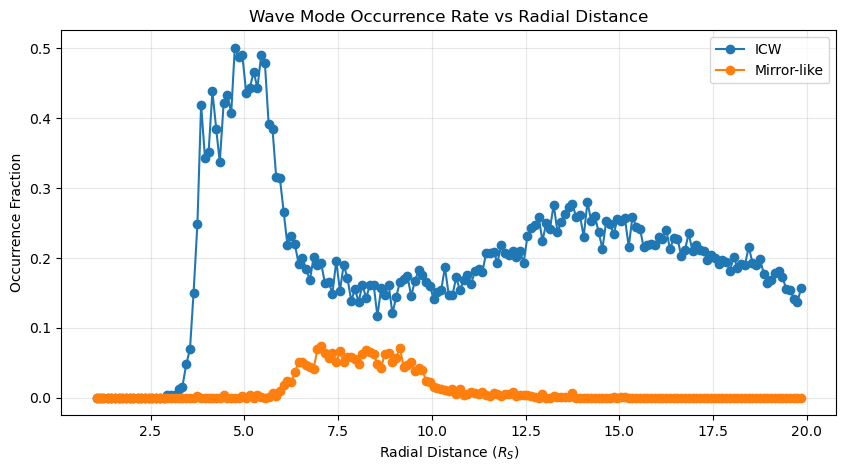

In [55]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    radial_stat['r_mean'],
    radial_stat['ICW_fraction'],
    marker='o',
    label='ICW'
)

ax.plot(
    radial_stat['r_mean'],
    radial_stat['mirror_fraction'],
    marker='o',
    label='Mirror-like'
)

# ax.plot(
#     radial_stat['r_mean'],
#     radial_stat['mixed_fraction'],
#     marker='o',
#     label='Mixed'
# )

ax.set_xlabel('Radial Distance ($R_S$)')
ax.set_ylabel('Occurrence Fraction')
ax.set_title('Wave Mode Occurrence Rate vs Radial Distance')
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

## plot test

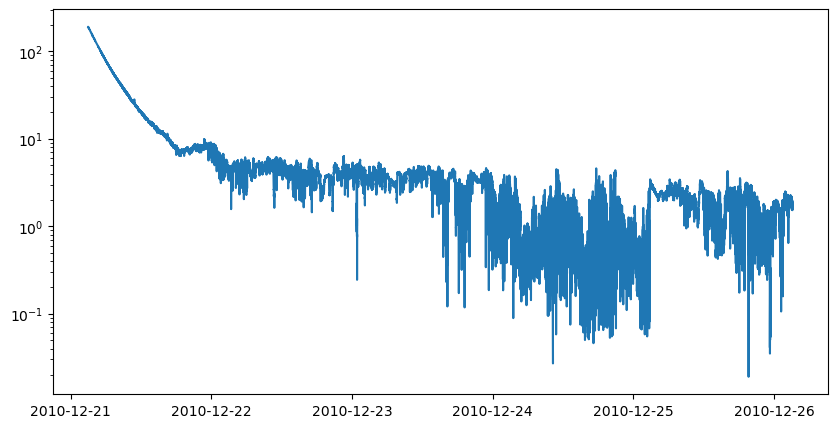

In [72]:
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(df['TIME'],df['BTOTAL'])
ax.set_yscale('log')

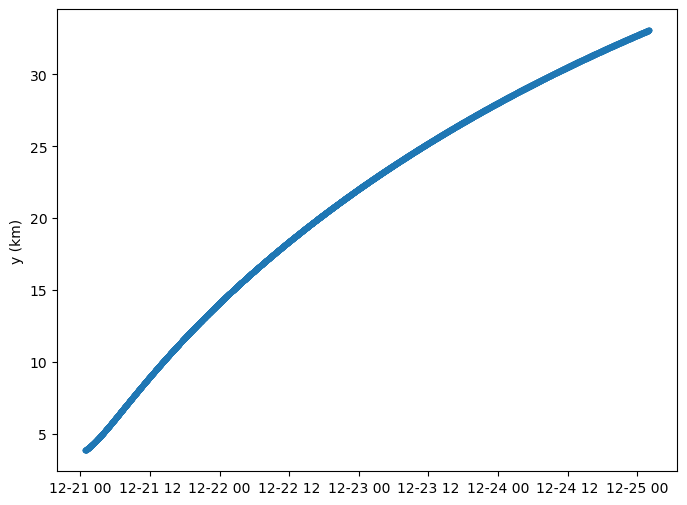

In [79]:
start_utc = pd.to_datetime("2010-12-21 00:50:00", utc=True)
end_utc  = pd.to_datetime("2010-12-25 02:00:00", utc=True)
n_points = 1000

#select the data in the given time range
mask = (cassini_location['utc'] >= start_utc) & (cassini_location['utc'] <= end_utc)
cassini_subset = cassini_location.loc[mask]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(cassini_subset['utc'], np.sqrt(cassini_subset['x_km']**2+cassini_subset['y_km']**2 + cassini_subset['z_km']**2)/60268, marker='o', linestyle='-', markersize=3)
ax.set_ylabel("y (km)")
# ax.set_title("Cassini Location in x-y plane from 2010-12-21 to 2010-12-22")
plt.show()